<a href="https://colab.research.google.com/github/alinas-git/Bank-Marketing-Deposit-Prediction/blob/main/BankMarketingPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Marketing: Term Deposit Subscription Prediction
Goal: predict whether a customer will subscribe to a term deposit (`deposit` = yes/no) after a marketing call, so the bank can target the right people.

importing the libraries

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

loading the dataset

In [45]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    path = "/content/drive/My Drive/Colab Notebooks/bank.csv"
except ImportError:
    path = "bank.csv"   # running locally: keep bank.csv next to the notebook

df = pd.read_csv(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Data Overview

In [46]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


exploring the dataset's insights

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [48]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [49]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [50]:
df.duplicated().sum()

np.int64(0)

* 11,162 customers and 17 columns, with **no missing values and no duplicates**.
* However, several categorical columns hide missing information inside an `"unknown"` category (`poutcome`, `contact`, `education`, `job`). Checking them below.

In [51]:
for col in ["job","education","contact","poutcome"]:
    print(col, ":", round((df[col]=="unknown").mean()*100,1), "% unknown")

job : 0.6 % unknown
education : 4.5 % unknown
contact : 21.0 % unknown
poutcome : 74.6 % unknown


* `poutcome` is ~75% unknown (most customers were never contacted in a previous campaign) and `contact` is ~21% unknown.
* I keep `unknown` as its own category instead of dropping rows, since it turns out to be informative (see the EDA).

#Data Cleaning

In [52]:
for col in ["default","housing","loan","deposit"]:
  df[col]=df[col].map({'yes':1,"no":0})

In [53]:
df['deposit'].unique()

array([1, 0])

`pdays = -1` means the customer was **never contacted before**, so it is a code and not a real number of days. I add a clear flag for it.

In [54]:
df['PreviouslyContacted'] = (df['pdays'] != -1).astype(int)

#Exploritry Data Analysis (EDA)

SETUP FOR PLOTTING

In [55]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize":(14,6),
    "axes.titlepad":10,
    "axes.titleweight":"bold",
    "axes.labelweight":"semibold",
    "axes.labelpad":10,
    "axes.titlecolor": "#301934",
    "axes.titlesize":14,
    "axes.labelsize":12,
    "grid.alpha":0.4,
    "grid.linestyle":"--",
    "grid.color":"pink",
    "grid.linewidth":2,
    "axes.grid":True
    })

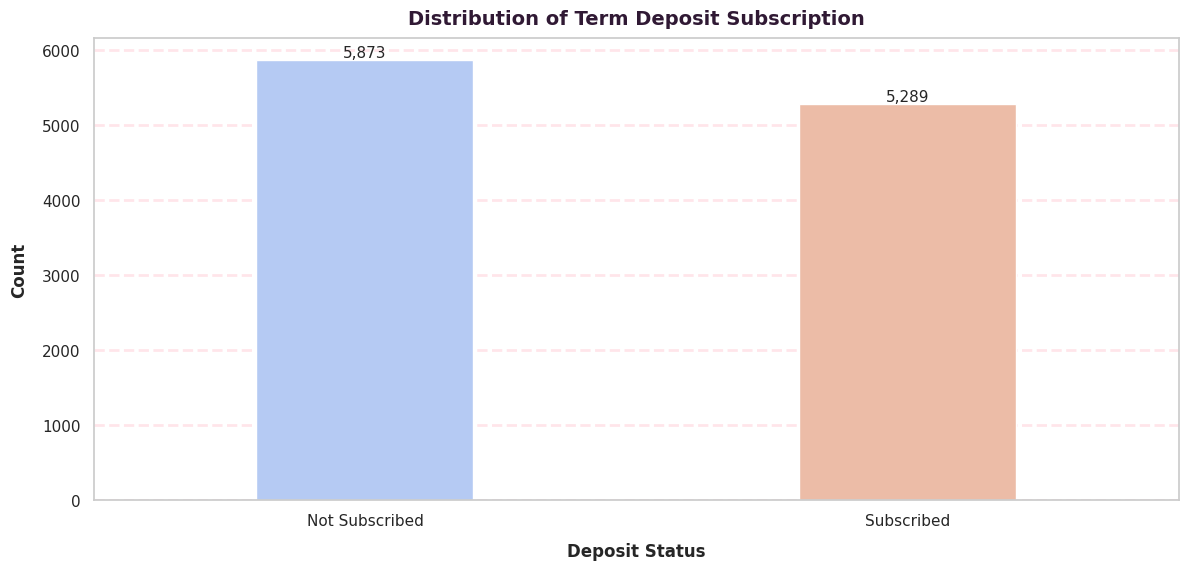

In [56]:
ax=sns.countplot(x="deposit",data=df,
              palette="coolwarm",
              width=0.4)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',size=11)

plt.title("Distribution of Term Deposit Subscription")
plt.xticks([0,1],["Not Subscribed","Subscribed"])
plt.xlabel("Deposit Status")
plt.ylabel("Count")
plt.show()

#Analysis Of Class Balance

* The classes here are **almost balanced**: 5,873 did not subscribe vs 5,289 who did (about 47% subscribed).
* So there is no need for `scale_pos_weight` or class weights, and accuracy is a fair metric. I still look at Precision, Recall and F1 because the bank cares about *who it should call*.

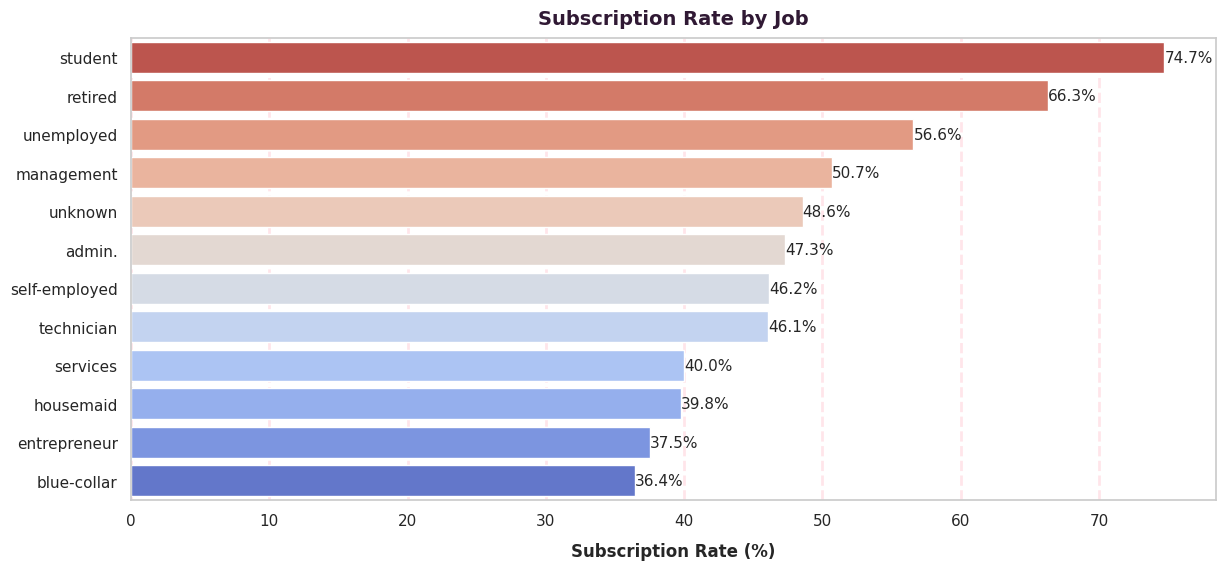

In [57]:
rate = df.groupby("job")["deposit"].mean().sort_values(ascending=False)
ax = sns.barplot(x=rate.values*100, y=rate.index, palette="coolwarm_r", orient="h")

for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%',
                (p.get_width(), p.get_y()+p.get_height()/2.),
                ha='left', va='center', size=11)

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("")
plt.show()

INSIGHTS:

* **Students (74.7%)** and **retired customers (66.3%)** subscribe the most.
* **Blue-collar (36.4%)** and **entrepreneurs (37.5%)** subscribe the least.
* Job clearly matters, the gap between the top and bottom groups is about 38 points.

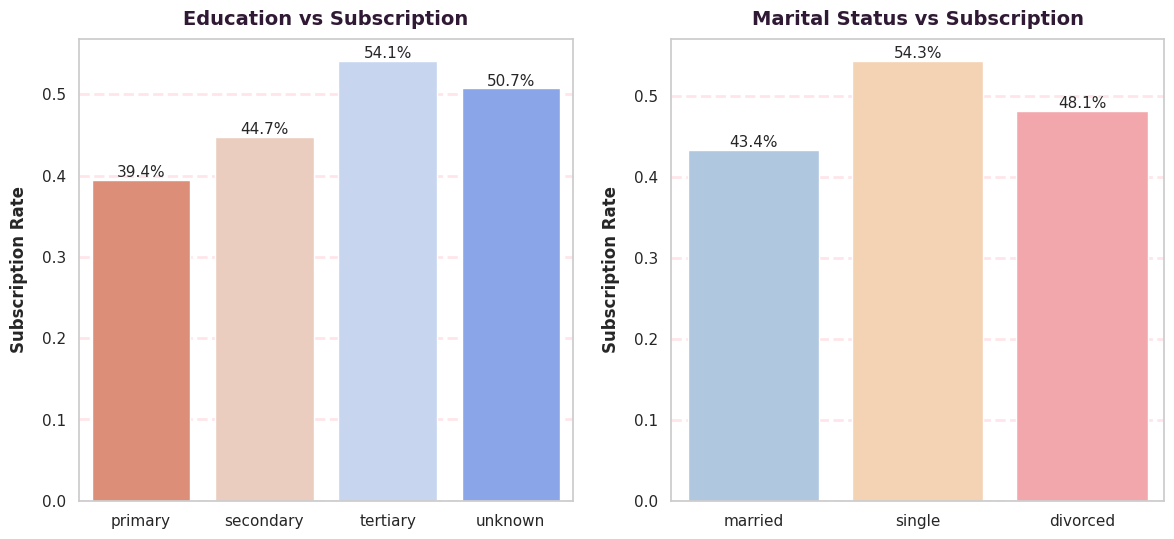

In [58]:
fig,axes=plt.subplots(1,2,figsize=(14,6))
order=["primary","secondary","tertiary","unknown"]
sns.barplot(data=df,x="education",y="deposit",order=order,errorbar=None,palette="coolwarm_r",ax=axes[0])
sns.barplot(data=df,x="marital",y="deposit",errorbar=None,palette=["#A7C7E7","#FFD1A9","#FF9AA2"],ax=axes[1])

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{p.get_height()*100:.1f}%',
                    (p.get_x()+p.get_width()/2., p.get_height()),
                    ha='center', va='bottom', size=11)
    ax.set_ylabel("Subscription Rate")
    ax.set_xlabel("")
axes[0].set_title("Education vs Subscription")
axes[1].set_title("Marital Status vs Subscription")
plt.show()

INSIGHTS:

* **Education:** the more educated, the more likely to subscribe: primary 39.4%, secondary 44.7%, tertiary 54.1%.
* **Marital status:** single customers subscribe most (54.3%), then divorced (48.1%), while married customers are lowest (43.4%).

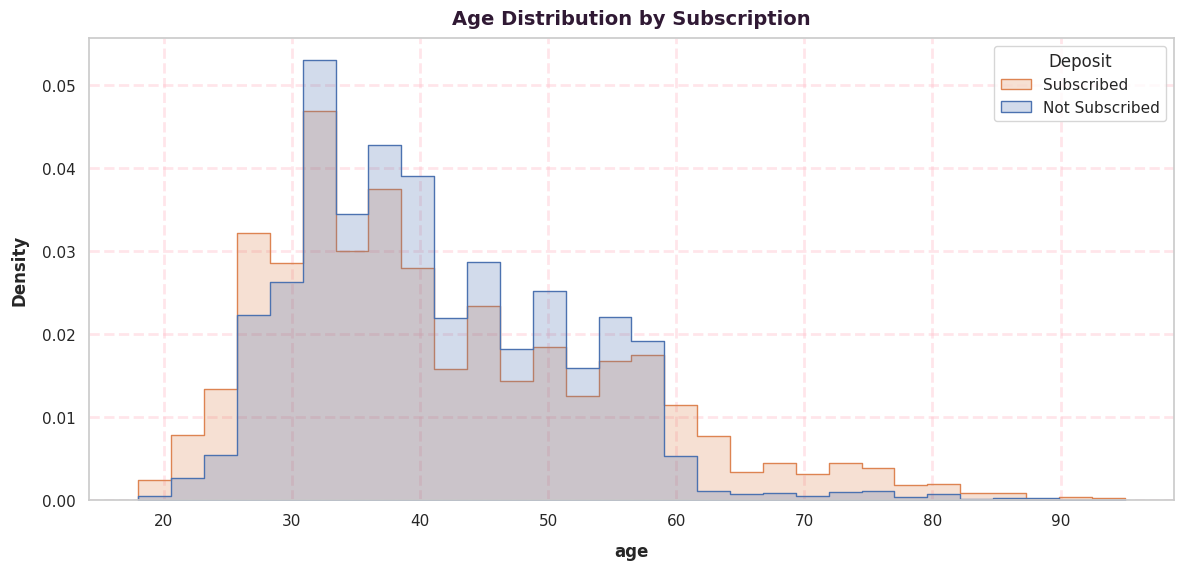

In [59]:
sns.histplot(data=df, x="age", hue="deposit", bins=30, element="step",
             stat="density", common_norm=False)
plt.legend(title="Deposit", labels=["Subscribed","Not Subscribed"])
plt.title("Age Distribution by Subscription")
plt.show()

age_groups = pd.cut(df["age"],[17,25,35,45,55,65,100],labels=["<=25","26-35","36-45","46-55","56-65","65+"])

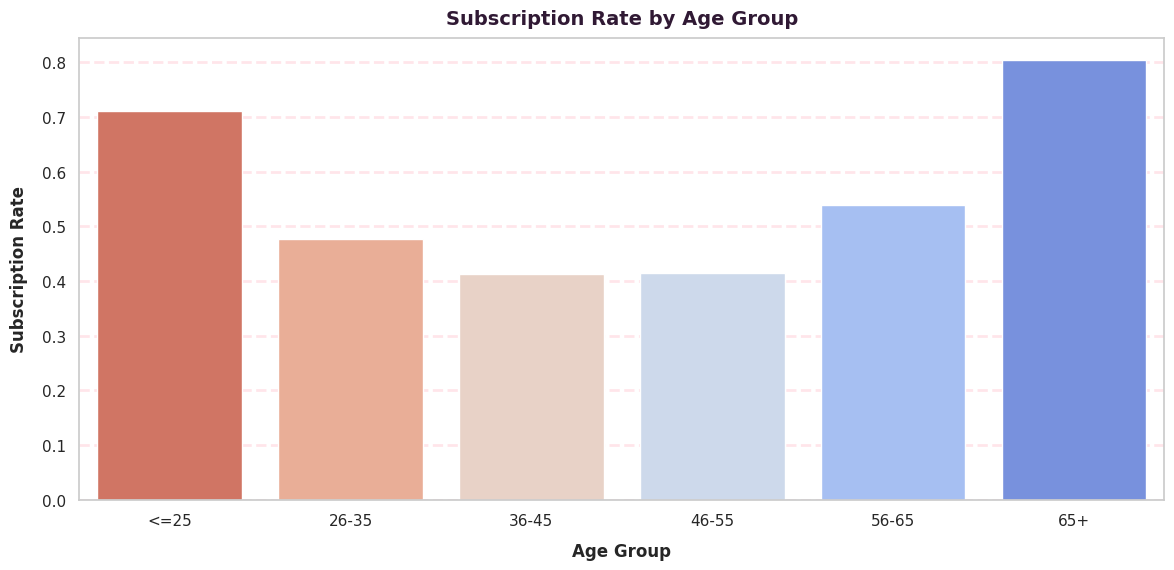

In [60]:
sns.barplot(x=age_groups, y=df["deposit"], errorbar=None, palette="coolwarm_r")
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%',
                (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom', size=11)
plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate")
plt.show()

INSIGHTS:

* The relationship with age is **U-shaped**: the youngest (<=25) subscribe at 71.1% and the oldest (65+) at 80.4%.
* The middle group (36-55) is the lowest at about 41%, and it is also where most customers are, so this is where the bank spends most of its calls with the least return.

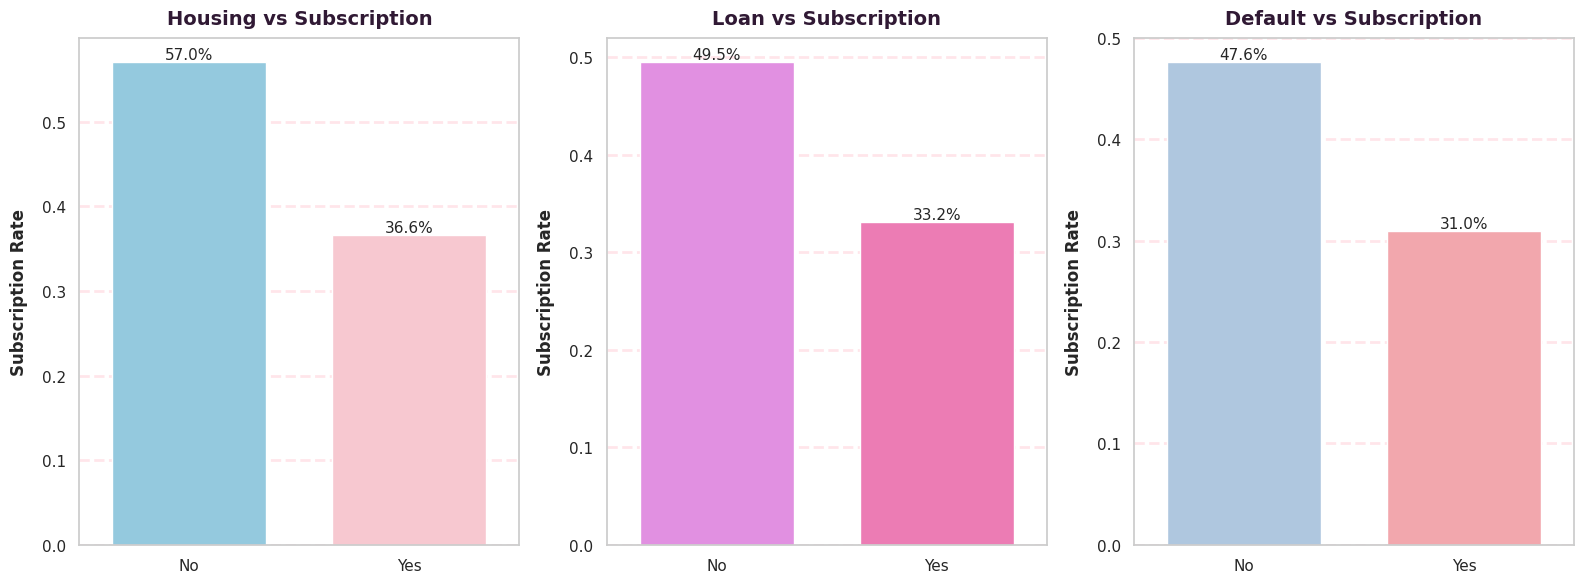

In [61]:
fig,axes=plt.subplots(1,3,figsize=(16,6))
for ax,col,pal in zip(axes,["housing","loan","default"],[["skyblue","pink"],["violet","hotpink"],["#A7C7E7","#FF9AA2"]]):
    sns.barplot(data=df,x=col,y="deposit",errorbar=None,palette=pal,width=0.7,ax=ax)
    ax.set_xticklabels(["No","Yes"])
    ax.set_title(f"{col.capitalize()} vs Subscription")
    ax.set_ylabel("Subscription Rate")
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f'{p.get_height()*100:.1f}%',
                    (p.get_x()+p.get_width()/2., p.get_height()),
                    ha='center', va='bottom', size=11)
plt.tight_layout()
plt.show()

INSIGHTS:

* **Housing loan:** customers *without* a housing loan subscribe at 57.0% vs 36.6% with one.
* **Personal loan:** 49.5% without vs 33.2% with one.
* **Credit default:** only 168 customers have defaulted, but they subscribe far less (31.0% vs 47.6%).
* Pattern: customers who already carry debt have less money to lock into a deposit.

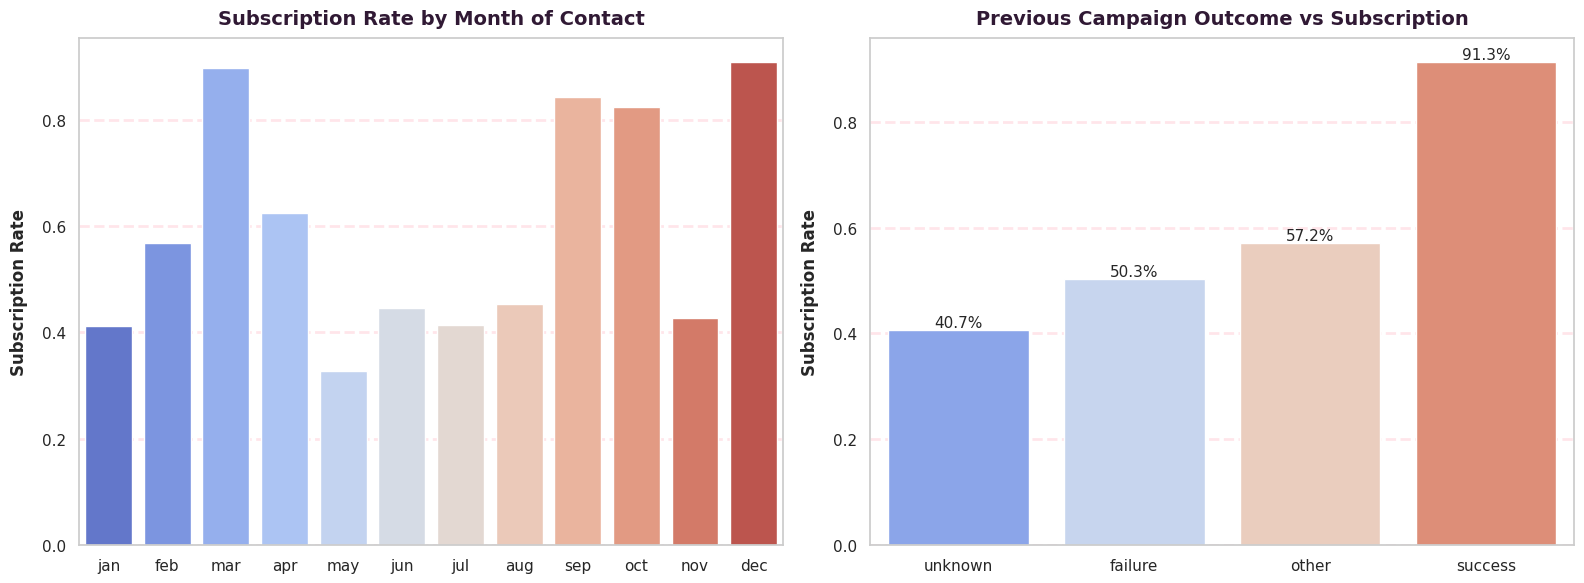

In [62]:
fig,axes=plt.subplots(1,2,figsize=(16,6))

sns.barplot(data=df,x="month",y="deposit",errorbar=None,palette="coolwarm",
            order=["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"],ax=axes[0])
axes[0].set_title("Subscription Rate by Month of Contact")
axes[0].set_ylabel("Subscription Rate")
axes[0].set_xlabel("")

order=["unknown","failure","other","success"]
sns.barplot(data=df,x="poutcome",y="deposit",order=order,errorbar=None,palette="coolwarm",ax=axes[1])
axes[1].set_title("Previous Campaign Outcome vs Subscription")
axes[1].set_ylabel("Subscription Rate")
axes[1].set_xlabel("")
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height()*100:.1f}%',
                (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom', size=11)
plt.tight_layout()
plt.show()

INSIGHTS:

* **Month:** a huge seasonal effect. December (90.9%), March (89.9%), September (84.3%) and October (82.4%) do very well, while **May is the worst at 32.8%** and also has the most calls (2,824), meaning the bank made the most calls when success was least likely.
  * Caution: the quiet months have very few calls (110 in December), so those rates are less reliable.
* **Previous outcome:** customers who subscribed to a previous campaign say yes **91.3%** of the time. Past success is one of the strongest signals in the data.

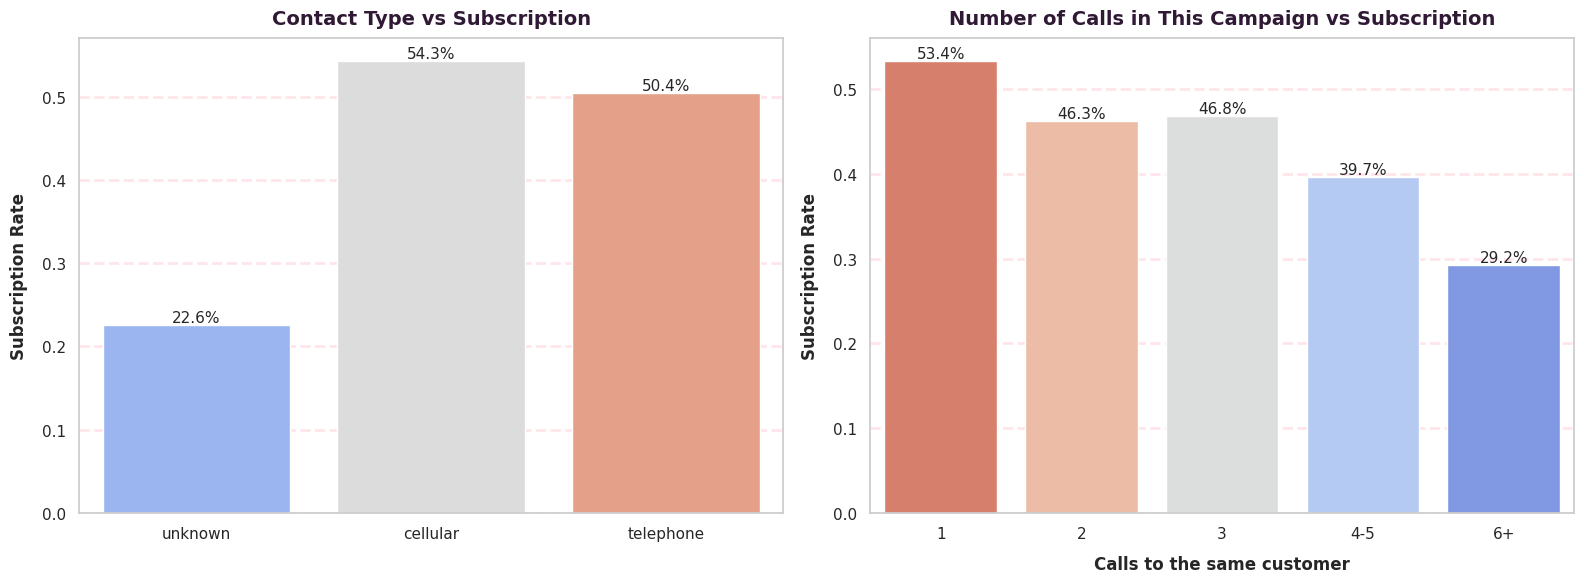

In [63]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
sns.barplot(data=df,x="contact",y="deposit",errorbar=None,palette="coolwarm",ax=axes[0])
axes[0].set_title("Contact Type vs Subscription")
axes[0].set_ylabel("Subscription Rate")
axes[0].set_xlabel("")

camp=pd.cut(df["campaign"],[0,1,2,3,5,100],labels=["1","2","3","4-5","6+"])
sns.barplot(x=camp,y=df["deposit"],errorbar=None,palette="coolwarm_r",ax=axes[1])
axes[1].set_title("Number of Calls in This Campaign vs Subscription")
axes[1].set_xlabel("Calls to the same customer")
axes[1].set_ylabel("Subscription Rate")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{p.get_height()*100:.1f}%',
                    (p.get_x()+p.get_width()/2., p.get_height()),
                    ha='center', va='bottom', size=11)
plt.tight_layout()
plt.show()

INSIGHTS:

* **Contact type:** when the contact method is `unknown`, the subscription rate is only 22.6% vs 54.3% for cellular.
* **Number of calls:** more calls does *not* mean more subscriptions. It falls from 53.4% (1 call) to 29.2% (6+ calls), so repeated calling mostly annoys customers.

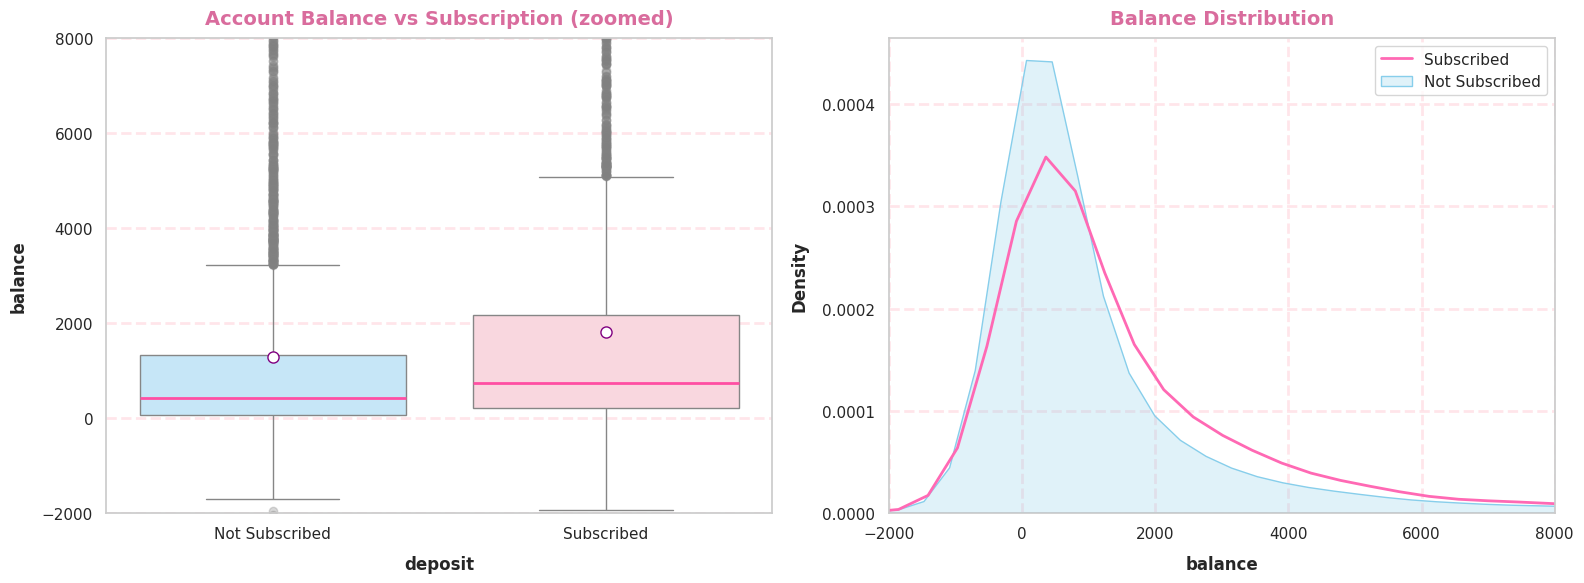

In [64]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
sns.boxplot(data=df,x="deposit",y="balance",palette=['#BEE9FF','#FFD1DC'],showmeans=True,
            meanprops={"marker":"o","mfc":"white","mec":"purple","ms":8},
            medianprops={'color':'#FF4FA3','lw':2},flierprops={'marker':'o','mfc':'gray','alpha':0.3},ax=axes[0])
axes[0].set_ylim(-2000,8000)
axes[0].set_title("Account Balance vs Subscription (zoomed)",color="#D96C9D")

sns.kdeplot(data=df[df["deposit"]==1],x="balance",lw=2,color="hotpink",label="Subscribed",ax=axes[1])
sns.kdeplot(data=df[df["deposit"]==0],x="balance",fill=True,color="skyblue",label="Not Subscribed",ax=axes[1])
axes[1].set_xlim(-2000,8000)
axes[1].set_title("Balance Distribution",color="#D96C9D")
axes[1].legend()
for ax in axes:
    ax.set_xlabel(ax.get_xlabel())
axes[0].set_xticklabels(["Not Subscribed","Subscribed"])
plt.tight_layout()
plt.show()

INSIGHTS:

* Subscribers have a higher balance: the **median is 733 vs 414** for non-subscribers (mean 1,804 vs 1,280).
* `balance` is very skewed (median 550, 99th percentile ~13,200, max 81,204), so I zoomed the plot. Tree models like XGBoost handle this skew fine, so I leave the outliers in.
* 688 customers have a negative balance (overdrawn).

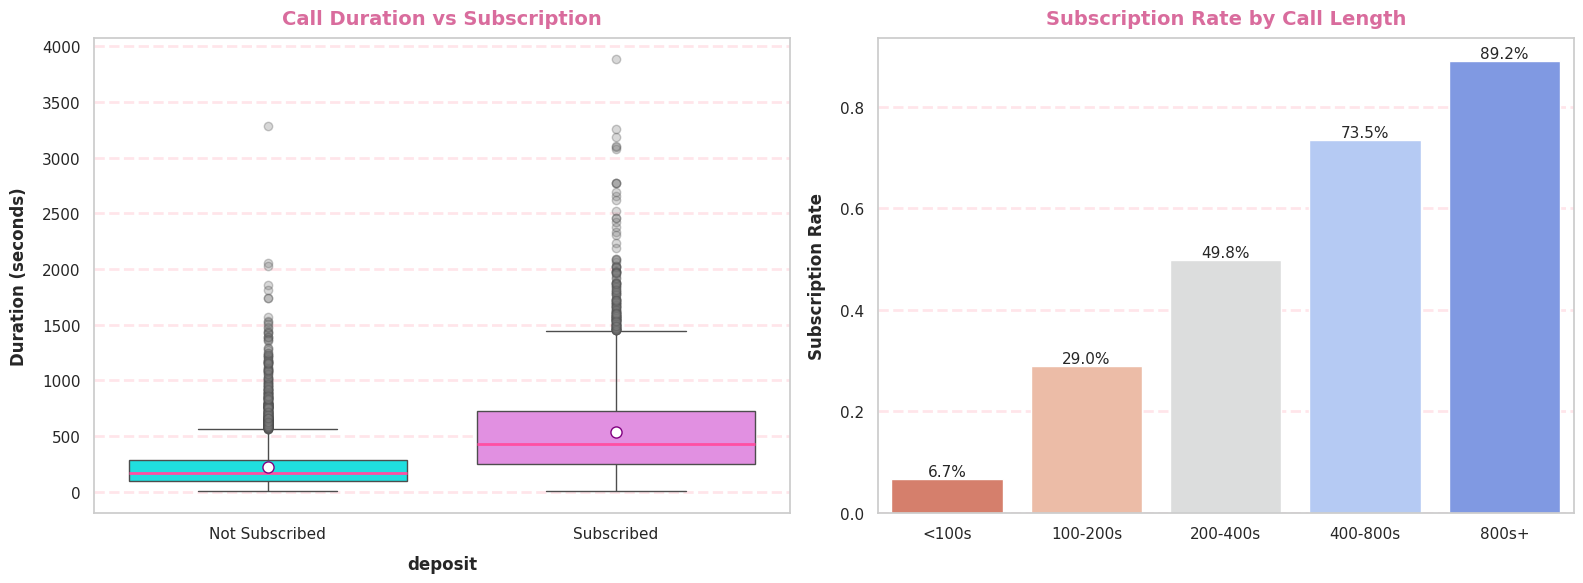

In [65]:
fig,axes=plt.subplots(1,2,figsize=(16,6))
sns.boxplot(data=df,x="deposit",y="duration",palette=['cyan','violet'],showmeans=True,
            meanprops={"marker":"o","mfc":"white","mec":"purple","ms":8},
            medianprops={'color':'#FF4FA3','lw':2},flierprops={'marker':'o','mfc':'gray','alpha':0.3},ax=axes[0])
axes[0].set_xticklabels(["Not Subscribed","Subscribed"])
axes[0].set_title("Call Duration vs Subscription",color="#D96C9D")
axes[0].set_ylabel("Duration (seconds)")

dur=pd.cut(df["duration"],[0,100,200,400,800,5000],labels=["<100s","100-200s","200-400s","400-800s","800s+"])
ax=sns.barplot(x=dur,y=df["deposit"],errorbar=None,palette="coolwarm_r",ax=axes[1])
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%',
                (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom', size=11)
axes[1].set_title("Subscription Rate by Call Length",color="#D96C9D")
axes[1].set_ylabel("Subscription Rate")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

INSIGHTS (and an important warning):

* Longer calls strongly match subscription: only 6.7% subscribe when the call is under 100s, but 89.2% when it is over 800s. The median call lasts 426s for subscribers vs 163s for non-subscribers.
* **Data leakage:** call duration is only known *after* the call ends, so it cannot be used to decide who to call. A model that uses it will look great on paper but be useless for real targeting.
* So the **main model drops `duration`**. I also train a version *with* it at the end just to show how much it inflates the scores.

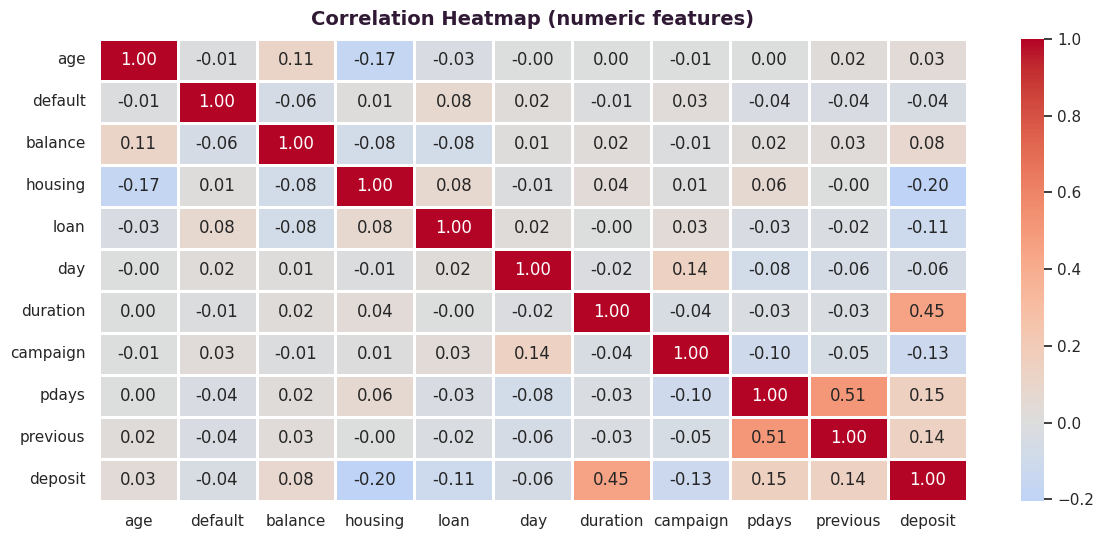

In [66]:
df_corr = df.select_dtypes("number").drop(columns=["PreviouslyContacted"])
sns.heatmap(df_corr.corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0,linewidths=1)
plt.title("Correlation Heatmap (numeric features)")
plt.show()

* Correlations between the numeric features are weak, so there is no multicollinearity problem.
* `deposit` is most correlated with `duration` (the leaky column), then with `previous` / `pdays` and `housing`.

#Encoding & Model Selection

In [67]:
X=df.drop(["deposit","duration"],axis=1)   # duration dropped on purpose (data leakage)
y=df["deposit"]

In [68]:
X=pd.get_dummies(X,drop_first=True)

In [69]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# 1.Logestic Regression

In [70]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=5000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=5000)

In [71]:
y_pred=model.predict(X_test)

In [72]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,roc_auc_score
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.67      0.82      0.74      1175
           1       0.73      0.56      0.64      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.70      0.69      2233



In [73]:
print(confusion_matrix(y_test,y_pred))

[[959 216]
 [462 596]]


In [74]:
LR_auc=roc_auc_score(y_test,model.predict_proba(X_test)[:,1])
print("Logistic Regression ROC-AUC:",round(LR_auc,3))

Logistic Regression ROC-AUC: 0.758


Since the classes are balanced, I don't use class weights here (unlike the loan default project). This is the baseline XGBoost has to beat.

# 2.XGBoost

In [75]:
from xgboost import XGBClassifier
XGB=XGBClassifier(random_state=42)
XGB.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [76]:
y_XGBpred=XGB.predict(X_test)
print(classification_report(y_test,y_XGBpred))
print(confusion_matrix(y_test,y_XGBpred))

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      1175
           1       0.74      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.72      0.72      0.72      2233
weighted avg       0.72      0.72      0.72      2233

[[942 233]
 [390 668]]


In [77]:
XGB_yprob=XGB.predict_proba(X_test)[:,1]
XGB_auc=roc_auc_score(y_test,XGB_yprob)
print("XGBoost ROC-AUC:",round(XGB_auc,3))

XGBoost ROC-AUC: 0.779


Trying different Thresholds

In [78]:
for i in [0.3,0.4,0.5,0.6,0.7]:
  temp_ypred=(XGB_yprob>i).astype(int)
  print(f"\n\nThreshold:{i}\n")
  print(classification_report(y_test,temp_ypred))
  print(confusion_matrix(y_test,temp_ypred))



Threshold:0.3

              precision    recall  f1-score   support

           0       0.75      0.54      0.63      1175
           1       0.61      0.80      0.69      1058

    accuracy                           0.66      2233
   macro avg       0.68      0.67      0.66      2233
weighted avg       0.68      0.66      0.66      2233

[[639 536]
 [213 845]]


Threshold:0.4

              precision    recall  f1-score   support

           0       0.73      0.70      0.71      1175
           1       0.68      0.71      0.69      1058

    accuracy                           0.70      2233
   macro avg       0.70      0.70      0.70      2233
weighted avg       0.70      0.70      0.70      2233

[[818 357]
 [308 750]]


Threshold:0.5

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      1175
           1       0.74      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.72      0.

Setting the final Threshold

In [79]:
FINAL_THRESHOLD = 0.5   # <- change this after comparing the thresholds above
XGB_ypred=(XGB_yprob>FINAL_THRESHOLD).astype(int)
print(classification_report(y_test,XGB_ypred))
print(confusion_matrix(y_test,XGB_ypred))

              precision    recall  f1-score   support

           0       0.71      0.80      0.75      1175
           1       0.74      0.63      0.68      1058

    accuracy                           0.72      2233
   macro avg       0.72      0.72      0.72      2233
weighted avg       0.72      0.72      0.72      2233

[[942 233]
 [390 668]]


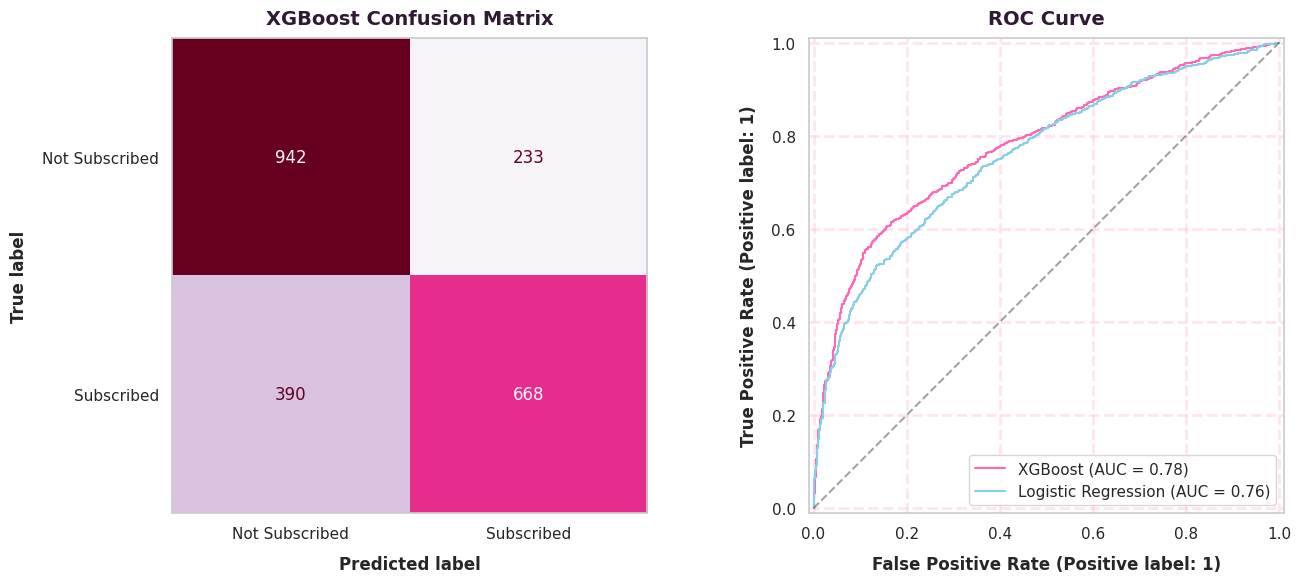

In [80]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig,axes=plt.subplots(1,2,figsize=(14,6))
ConfusionMatrixDisplay.from_predictions(y_test,XGB_ypred,display_labels=["Not Subscribed","Subscribed"],cmap="PuRd",ax=axes[0],colorbar=False)
axes[0].set_title("XGBoost Confusion Matrix")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test,XGB_yprob,name="XGBoost",color="hotpink",ax=axes[1])
RocCurveDisplay.from_estimator(model,X_test,y_test,name="Logistic Regression",color="skyblue",ax=axes[1])
axes[1].plot([0,1],[0,1],"k--",alpha=0.4)
axes[1].set_title("ROC Curve")
plt.tight_layout()
plt.show()

7. Model Comparison & Selection:

(Fill in after running: compare the Logistic Regression and XGBoost accuracy, recall for the *subscribed* class and ROC-AUC, and say which threshold you chose and why.)

In [81]:
featureDF=pd.DataFrame({
    "Feature":X.columns,
    "Importance":XGB.feature_importances_})
featureDf=featureDF.sort_values(by="Importance",ascending=False)
featureDf.head(10)

,Feature,Importance
40,poutcome_success,0.347569
27,contact_unknown,0.097391
34,month_mar,0.064171
33,month_jun,0.035583
37,month_oct,0.029068
38,month_sep,0.028048
29,month_dec,0.024242
3,housing,0.021668
30,month_feb,0.020066
28,month_aug,0.019945


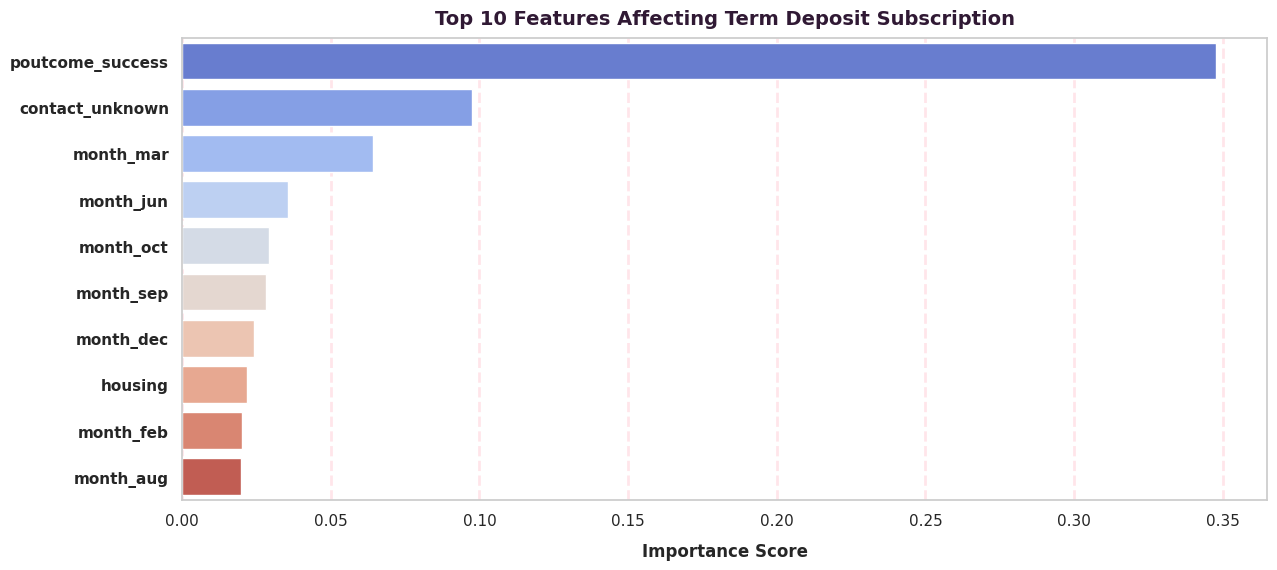

In [82]:
sns.barplot(orient="h",data=featureDf.head(10),x="Importance",y="Feature",palette="coolwarm")
plt.ylabel("")
plt.title("Top 10 Features Affecting Term Deposit Subscription")
plt.yticks(fontweight="semibold")
plt.xlabel("Importance Score")
plt.show()

#Bonus: What happens if we keep `duration`?

To show the leakage problem, I train the same model with call duration included.

In [83]:
X_leak=pd.get_dummies(df.drop(["deposit"],axis=1),drop_first=True)
Xl_train,Xl_test,yl_train,yl_test=train_test_split(X_leak,y,test_size=0.2,random_state=42,stratify=y)

XGB_leak=XGBClassifier(random_state=42)
XGB_leak.fit(Xl_train,yl_train)
leak_prob=XGB_leak.predict_proba(Xl_test)[:,1]
print("Without duration -> Accuracy:",round(accuracy_score(y_test,XGB_ypred),3)," ROC-AUC:",round(XGB_auc,3))
print("With duration    -> Accuracy:",round(accuracy_score(yl_test,(leak_prob>0.5).astype(int)),3)," ROC-AUC:",round(roc_auc_score(yl_test,leak_prob),3))

Without duration -> Accuracy: 0.721  ROC-AUC: 0.779
With duration    -> Accuracy: 0.857  ROC-AUC: 0.927


The version with `duration` scores noticeably higher, but that is **not** a real improvement: the call length is not known before calling. The realistic model is the one without it.

# Wrap up & Final Model Conclusion

(Fill in after running, using the same structure as the loan default project: the final model and threshold, its recall / precision / accuracy for the *subscribed* class, and what that means for the bank.)

### Key business takeaways from the EDA
* **Who to target:** students, retired customers, single and highly educated customers, and customers without housing or personal loans.
* **When to call:** September to December and March work well, while May has the most calls but the lowest success rate.
* **Past success matters:** customers who said yes in a previous campaign say yes again 91% of the time.
* **Don't over-call:** subscription rates fall as the number of calls to the same person grows, with 6+ calls at only 29%.
* **Fix the data:** `contact = unknown` has just a 22.6% rate, so better contact tracking would help.